# Metodología 1 — Diccionario (co-ocurrencia)

Cuenta **palabras de incertidumbre que aparecen junto a una palabra de
categoría**, expresado como tasa por cada 1,000 palabras. Cinco listas de
términos, cinco series.

| serie | qué mide |
|---|---|
| `policy` | incertidumbre sobre la política monetaria — el índice general |
| `inflation` | incertidumbre sobre la inflación — **el que reportamos como principal** |
| `cambiario` | incertidumbre sobre el tipo de cambio |
| `growth` | incertidumbre sobre el crecimiento |
| `geopolitical` | incertidumbre geopolítica |

**Por qué así y no como EPU.** Baker-Bloom-Davis y Husted trabajan sobre
periódicos, donde lo difícil es encontrar el ~2% de artículos que hablan del
banco central: para eso sirven sus términos de "política" e "institución". En un
documento de Banxico ese trabajo ya lo hizo la elección del corpus — todo el
documento es el banco central hablando de política monetaria — así que esos
términos coinciden casi siempre y no discriminan nada. Medido directamente,
exigir el nombre de la institución empeoraba el índice.

Cieslak, Hansen, McMahon & Xiao (NBER 31849) enfrentan lo mismo en las
transcripciones del FOMC y lo resuelven preguntando a qué **tema** se adhiere la
incertidumbre, contando **palabras** en lugar de documentos, y dentro de una
**oración** en lugar de en todo un pasaje. Esta es esa construcción.

**Dos decisiones de normalización que importan:**

1. **Palabras por cada 1,000 palabras, no fracción de chunks.** Las minutas casi
   duplicaron su longitud desde 2011, así que un denominador de "fracción de
   chunks" sube solo por eso. Una tasa por palabra no. Además significa que esta
   metodología **no usa chunks**, y por lo tanto no tiene el problema de
   agregación que sí tienen la 2 y la 3.
2. **Misma oración, o una a cada lado.** Dentro de un pasaje de 3,000 caracteres
   casi cualquier par de palabras coincide; la cercanía es lo que hace que la
   co-ocurrencia signifique algo.

**Ojo:** las listas de palabras se construyeron (semillas expandidas con word2vec y depuradas a mano)
sobre los Informes Trimestrales, un corpus anterior del proyecto. Por eso este método funciona mal en
anuncios y minutas: es uno de los resultados de la presentación.

Escribe `banxico_{anuncios,minutas}_index_exact_matching.parquet`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# El código vive en src/, agrupado en corpus/ index/ analysis/ (sin __init__.py):
# hay que agregar cada subcarpeta a la ruta de Python. Ver src/paths.py.
sys.path.insert(0, str(Path.cwd().parent / "src"))
import paths
paths.add_src_subfolders_to_path()

from exact_matching import (
    DEFAULT_UNCERTAINTY_TERMS,
    DEFAULT_COOCCURRENCE_CATEGORIES,
    compute_cooccurrence_rates,
)
from common import standardize_to_index

In [2]:
# Los dos corpus. Cada uno produce su propio índice: un valor por documento.
CORPORA = ["banxico_anuncios", "banxico_minutas"]

## Los diccionarios

Están en `src/index/exact_matching.py` como parámetros: otra lista mide otro concepto sin tocar la lógica.

Ninguna palabra está en la lista de incertidumbre **y** en una de categoría: si lo
estuviera, una sola palabra satisfaría las dos mitades de la co-ocurrencia y la
medida dejaría de significar algo.

In [3]:
print(f"INCERTIDUMBRE ({len(DEFAULT_UNCERTAINTY_TERMS)} términos)")
print("  " + ", ".join(DEFAULT_UNCERTAINTY_TERMS))
print()
for name, terms in DEFAULT_COOCCURRENCE_CATEGORIES.items():
    print(f"{name.upper()} ({len(terms)} términos)")
    print("  " + ", ".join(terms))
    print()

# Verificacion: ninguna palabra puede estar de los dos lados.
overlaps = {n: sorted(set(t) & set(DEFAULT_UNCERTAINTY_TERMS))
            for n, t in DEFAULT_COOCCURRENCE_CATEGORIES.items()}
assert not any(overlaps.values()), f"palabras en ambos lados: {overlaps}"
print("OK: ninguna palabra aparece en ambos lados de la co-ocurrencia")

INCERTIDUMBRE (58 términos)
  acentuado, acontecimientos, adverso, afectar, aversión, balance, complejidad, complejo, complicado, continúa, deteriorado, deterioro, deterioró, dificulta, difícil, duda, elevada, enfrenta, enfrentado, enfrentando, episodios, evento, exposición, incertidumbre, incierta, inciertas, incierto, inciertos, incumplimiento, inflacionario, inflacionarios, intensificación, manifestado, materialización, panorama, percepción, persiste, persisten, perspectivas, posibilidad, posible, preocupación, presiones, prevalece, prevalecen, prevista, profundidad, pudiera, pudieran, pérdidas, repercusiones, retos, riesgo, riesgos, sesgado, sesgo, tensiones, volatilidad

POLICY (22 términos)
  autoridad, conducción, convergencia, decisiones, decisión, desinflacionario, estrategia, futuras, junta, mantener, meta, monetaria, objetivo, objetivos, política, postura, referencia, restricción, restrictiva, restrictivo, reunión, tasa

INFLATION (18 términos)
  agregada, aumentos, ausencia

## Calcular las cinco series, para cada corpus

In [4]:
indices = {}
for corpus in CORPORA:
    documents = pd.read_parquet(paths.PROCESSED_DIR / f"{corpus}_documents.parquet")
    documents = documents.sort_values("publication_date").reset_index(drop=True)

    rates = compute_cooccurrence_rates(documents)
    rates = rates.merge(documents[["document_id", "publication_date", "title"]], on="document_id")
    rates = rates.sort_values("publication_date").reset_index(drop=True)

    RATE_COLUMNS = [c for c in rates.columns if c.startswith("unc_rate_")]
    for column in RATE_COLUMNS:
        rates[f"idx_{column}"] = standardize_to_index(rates[column])

    rates.to_parquet(paths.PROCESSED_DIR / f"{corpus}_index_exact_matching.parquet", index=False)
    indices[corpus] = rates
    print(f"{corpus}: {len(documents)} documentos, "
          f"{documents['document_text'].str.split().str.len().sum():,} palabras -> guardado")
    print("palabras de incertidumbre por cada 1,000 palabras:")
    display(rates[RATE_COLUMNS].describe().loc[["mean", "std", "min", "max"]].round(2))

banxico_anuncios: 238 documentos, 201,394 palabras -> guardado
palabras de incertidumbre por cada 1,000 palabras:


,unc_rate_policy,unc_rate_inflation,unc_rate_cambiario,unc_rate_growth,unc_rate_geopolitical
mean,15.31,19.95,7.37,16.19,3.59
std,9.20,9.86,6.58,8.47,6.53
min,0.00,3.13,0.00,0.00,0.00
max,43.13,46.94,27.91,41.42,30.57


banxico_minutas: 126 documentos, 837,287 palabras -> guardado
palabras de incertidumbre por cada 1,000 palabras:


,unc_rate_policy,unc_rate_inflation,unc_rate_cambiario,unc_rate_growth,unc_rate_geopolitical
mean,16.37,17.02,5.24,15.63,2.81
std,3.75,3.52,2.50,4.44,2.61
min,7.00,9.45,1.37,6.72,0.00
max,27.50,28.33,12.26,27.43,14.05


### Cómo leer esta tabla

Cada número es *palabras de incertidumbre adheridas a esa categoría, por cada
1,000 palabras del documento*. Las categorías **no suman** al total: una misma
palabra puede contar para dos categorías si la oración menciona ambas.

`geopolitical` es deliberadamente rara — casi cero antes de 2022 — así que su
serie es intermitente, no un índice suave. Eso es honesto, pero hay que tenerlo
en cuenta al interpretarla.

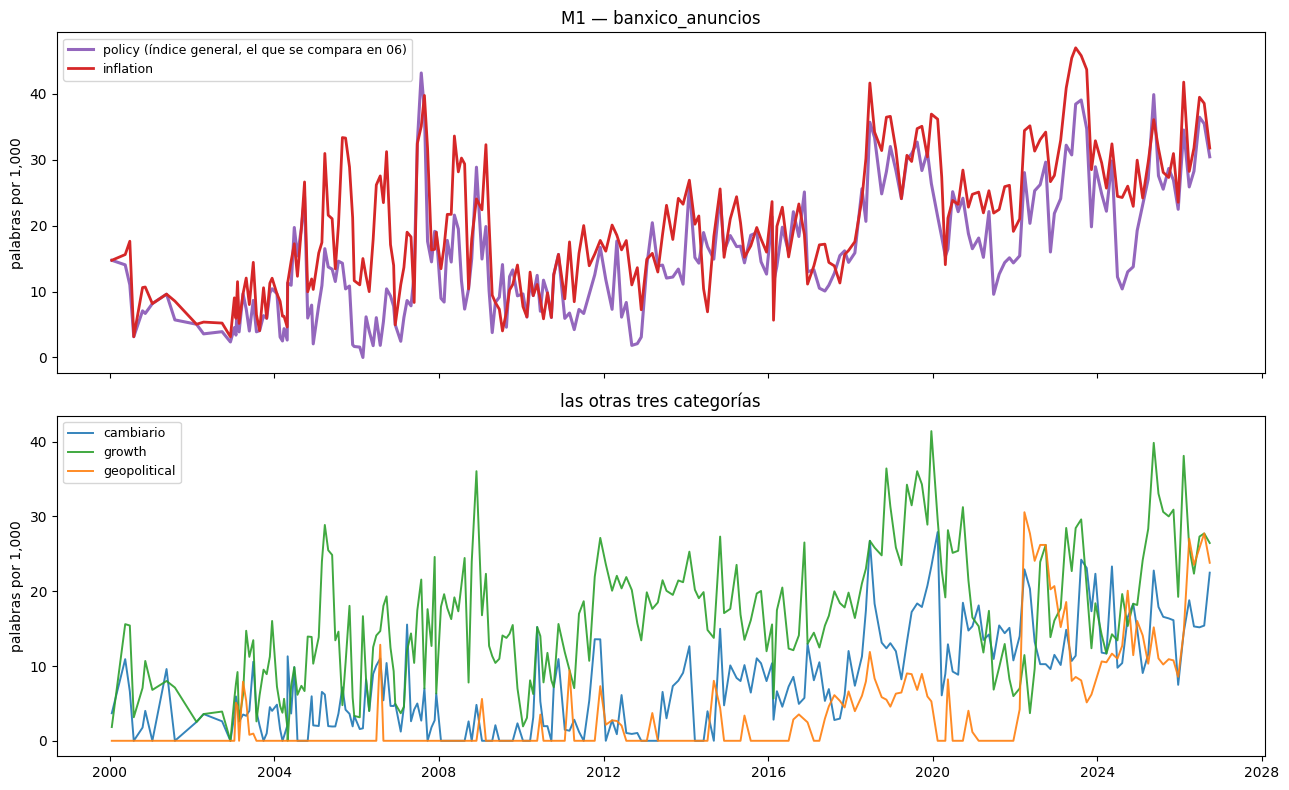

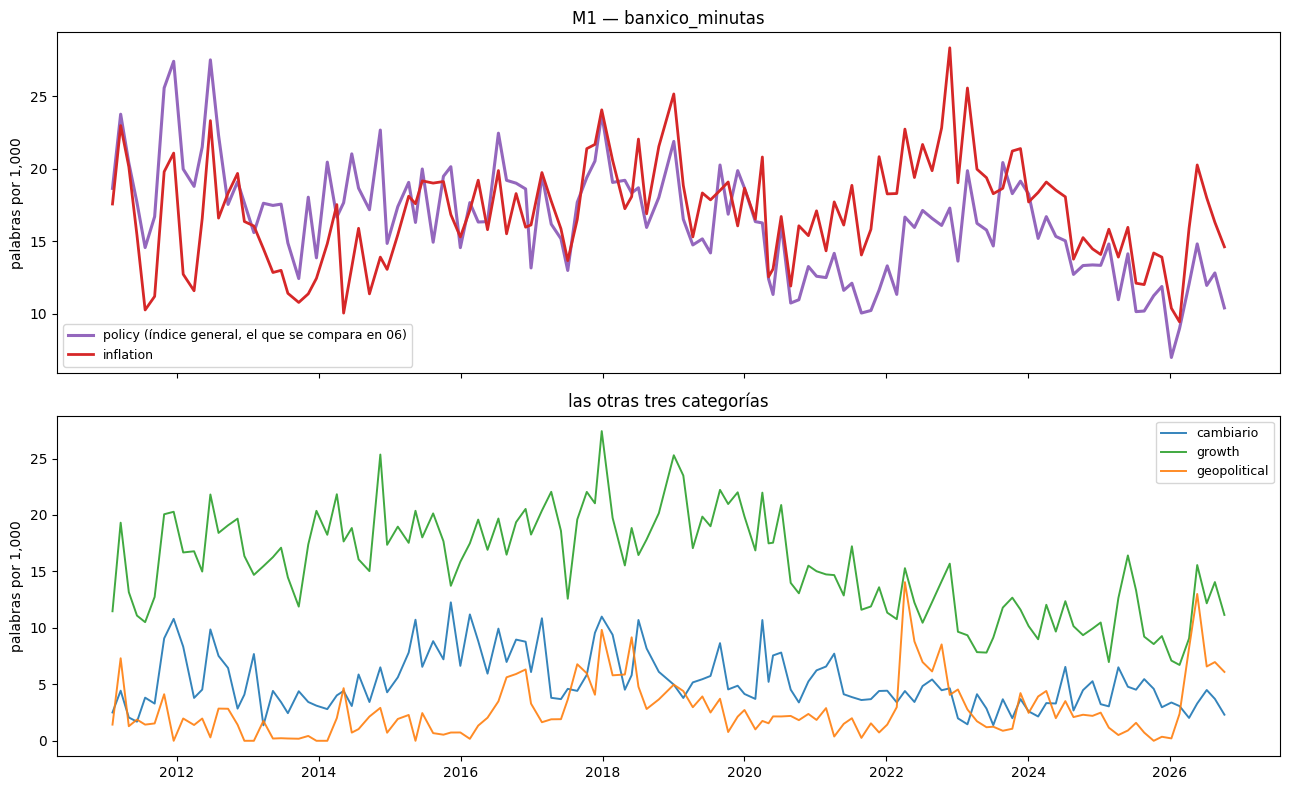

In [5]:
for corpus, rates in indices.items():
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    axes[0].plot(rates["publication_date"], rates["unc_rate_policy"],
                 lw=2.2, color="tab:purple", label="policy (índice general, el que se compara en 06)")
    axes[0].plot(rates["publication_date"], rates["unc_rate_inflation"], lw=2.0, color="tab:red", label="inflation")
    axes[0].set_ylabel("palabras por 1,000"); axes[0].set_title(f"M1 — {corpus}"); axes[0].legend(fontsize=9)
    for column, color in [("unc_rate_cambiario", "tab:blue"), ("unc_rate_growth", "tab:green"),
                          ("unc_rate_geopolitical", "tab:orange")]:
        axes[1].plot(rates["publication_date"], rates[column], lw=1.4, alpha=0.9, color=color,
                     label=column.replace("unc_rate_", ""))
    axes[1].set_ylabel("palabras por 1,000"); axes[1].set_title("las otras tres categorías"); axes[1].legend(fontsize=9)
    plt.tight_layout(); plt.show()

## ¿Las categorías miden cosas distintas?

Si las cinco series estuvieran casi perfectamente correlacionadas entre sí, la
descomposición por categoría no estaría aportando nada y bastaría con una sola
serie.

In [6]:
for corpus, rates in indices.items():
    print(corpus)
    display(rates[[c for c in rates.columns if c.startswith("unc_rate_")]]
            .rename(columns=lambda c: c.replace("unc_rate_", "")).corr().round(2))

banxico_anuncios


,policy,inflation,cambiario,growth,geopolitical
policy,1.00,0.81,0.63,0.68,0.53
inflation,0.81,1.00,0.65,0.66,0.54
cambiario,0.63,0.65,1.00,0.48,0.56
growth,0.68,0.66,0.48,1.00,0.35
geopolitical,0.53,0.54,0.56,0.35,1.00


banxico_minutas


,policy,inflation,cambiario,growth,geopolitical
policy,1.00,0.47,0.39,0.56,0.13
inflation,0.47,1.00,0.25,0.26,0.41
cambiario,0.39,0.25,1.00,0.54,0.01
growth,0.56,0.26,0.54,1.00,0.11
geopolitical,0.13,0.41,0.01,0.11,1.00
